# Criterios de información AIC y BIC: fundamentos matemáticos, interpretación y aplicación en modelos de series de tiempo

Los criterios de información **AIC** (*Akaike Information Criterion*) y **BIC** (*Bayesian Information Criterion*) son herramientas estadísticas utilizadas para comparar modelos matemáticos y seleccionar aquellos que ofrecen un equilibrio adecuado entre la capacidad de ajuste a los datos y la complejidad del modelo.

En el análisis de series de tiempo, estos criterios son especialmente importantes para seleccionar el orden de modelos autorregresivos $AR(p)$, de medias móviles $MA(q)$ y combinaciones como $ARMA(p,q)$ y $ARIMA(p,d,q)$.

La idea central es:

*Un modelo más complejo puede ajustarse mejor a los datos observados, pero esto no significa necesariamente que tenga una mayor capacidad de generalización o predicción.*

## 1. El problema de la selección de modelos

Supongamos que disponemos de una serie temporal de temperatura ambiental:

$$T_1, T_2, T_3, \dots, T_n$$

Nuestro objetivo consiste en construir un modelo que permita representar su comportamiento temporal y realizar predicciones.

Podríamos considerar distintos modelos:

$$AR(1), \quad AR(2), \quad AR(3)$$

$$MA(1), \quad MA(2), \quad MA(3)$$

$$ARMA(1,1), \quad ARMA(2,1)$$

Cada uno posee un número diferente de parámetros.

Por ejemplo, el modelo $AR(1)$:

$$T_t = c + \phi_1 T_{t-1} + \varepsilon_t$$

contiene un coeficiente autorregresivo $\phi_1$, mientras que $AR(2)$:

$$T_t = c + \phi_1 T_{t-1} + \phi_2 T_{t-2} + \varepsilon_t$$

incorpora dos coeficientes autorregresivos.

Si aumentamos progresivamente el orden $p$, el modelo adquiere mayor flexibilidad para representar las observaciones.

Sin embargo, esto introduce un problema: el **sobreajuste** (*overfitting*).

Un modelo con demasiados parámetros puede aprender fluctuaciones particulares de los datos de entrenamiento que no representan adecuadamente el comportamiento general de la serie.

Los criterios AIC y BIC permiten abordar este problema penalizando la complejidad del modelo.

## 2. Fundamento estadístico: la función de verosimilitud

Antes de estudiar AIC y BIC es necesario comprender el concepto de verosimilitud.

Supongamos que tenemos un modelo probabilístico caracterizado por un vector de parámetros:

$$\boldsymbol{\theta}=(\theta_1, \theta_2, \dots, \theta_k)$$

Y disponemos de las observaciones:

$$X=(X_1, X_2, \dots, X_n)$$

La función de verosimilitud se define como:

$$L(\boldsymbol{\theta};X)=f(X\mid\boldsymbol{\theta})$$

Donde $f$ representa la función de densidad o probabilidad conjunta de las observaciones bajo el modelo.

La verosimilitud cuantifica qué tan compatibles son los datos observados con determinados valores de los parámetros.

El método de máxima verosimilitud busca:

$$\hat{\boldsymbol{\theta}}=\arg\max_{\boldsymbol{\theta}}L(\boldsymbol{\theta};X)$$

En la práctica se utiliza el logaritmo de la verosimilitud:

$$\ell(\boldsymbol{\theta})=\ln L(\boldsymbol{\theta};X)$$

Y se determina:

$$\hat{\boldsymbol{\theta}}=\arg\max_{\boldsymbol{\theta}}\ell(\boldsymbol{\theta})$$

Maximizar la log-verosimilitud equivale a maximizar la verosimilitud, pero resulta numéricamente más conveniente.

En los modelos de series de tiempo, la función de verosimilitud incorpora la estructura probabilística del proceso y su dependencia temporal.

## 3. Criterio de información de Akaike (AIC)

El criterio AIC fue desarrollado por Hirotugu Akaike en 1974.

Su formulación general es:

$$AIC=2k-2\ln(\hat L)$$

También puede escribirse como:

$$AIC=-2\ell(\hat{\boldsymbol{\theta}})+2k$$

Donde:

| Símbolo | Significado |
| :--- | :--- |
| $AIC$ | Criterio de información de Akaike |
| $k$ | Número de parámetros libres estimados |
| $\hat L$ | Máximo valor de la función de verosimilitud |
| $\ell(\hat{\boldsymbol{\theta}})$ | Log-verosimilitud maximizada |

La ecuación contiene dos componentes.

### 3.1 Componente de ajuste

$$-2\ln(\hat L)$$

Este término evalúa la calidad del ajuste probabilístico.

Cuando un modelo presenta mayor log-verosimilitud, este componente disminuye.

Por tanto:

$$\text{Mayor log-verosimilitud} \Rightarrow \text{Menor término de desajuste}$$

### 3.2 Penalización por complejidad

$$2k$$

Este término penaliza la incorporación de parámetros.

Cada parámetro adicional aumenta la penalización en dos unidades.

Por ejemplo:

| Parámetros $k$ | Penalización AIC |
| :---: | :---: |
| 2 | 4 |
| 3 | 6 |
| 4 | 8 |
| 5 | 10 |
| 10 | 20 |

Así, un modelo más complejo debe conseguir una mejora suficiente de la log-verosimilitud para justificar sus parámetros adicionales.

### 3.3 Interpretación

La regla fundamental es:

$$\boxed{\text{Se prefiere el modelo con menor AIC}}$$

Pero hay una condición importante: los modelos deben ajustarse sobre observaciones comparables, utilizando una definición coherente de la verosimilitud.

El valor absoluto de AIC no es una medida directa de precisión predictiva.

Por ejemplo, un AIC de $-500$ no significa que el modelo tenga un error de predicción menor que 500 unidades.

AIC es un criterio relativo de comparación.

## 4. Criterio de información bayesiano (BIC)

El criterio BIC fue propuesto por Gideon Schwarz en 1978.

Su formulación es:

$$\boxed{BIC=k\ln(n)-2\ln(\hat L)}$$

O equivalentemente:

$$\boxed{BIC=-2\ell(\hat{\boldsymbol{\theta}})+k\ln(n)}$$

Donde:
- $k$: número de parámetros estimados.
- $n$: número de observaciones.
- $\hat L$: máxima verosimilitud.

La diferencia principal respecto al AIC se encuentra en la penalización.

Mientras que AIC utiliza:

$$P_{AIC}=2k$$

BIC utiliza:

$$P_{BIC}=k\ln(n)$$

Esto significa que la penalización del BIC depende tanto del número de parámetros como del tamaño de la muestra.

### 4.1 Efecto del tamaño de la muestra

Consideremos tres tamaños de muestra.

| Observaciones $n$ | Penalización por parámetro AIC | Penalización por parámetro BIC |
| :---: | :---: | :---: |
| 100 | 2.00 | 4.61 |
| 1,000 | 2.00 | 6.91 |
| 10,000 | 2.00 | 9.21 |

Observamos que AIC mantiene constante la penalización por parámetro.

En cambio, BIC incrementa la penalización conforme aumenta el número de observaciones.

Por esta razón, para muestras suficientemente grandes, BIC tiende a favorecer modelos más parsimoniosos.

## 5. Comparación matemática entre AIC y BIC

Las expresiones son:

$$AIC=-2\ln(\hat L)+2k$$

$$BIC=-2\ln(\hat L)+k\ln(n)$$

Restando ambas ecuaciones:

$$BIC-AIC=k\ln(n)-2k$$

Factorizando:

$$\boxed{BIC-AIC=k[\ln(n)-2]}$$

De esta expresión se obtiene que:
- Si $n > e^2$, BIC penaliza más que AIC.
- Si $n = e^2$, ambos aplican la misma penalización.
- Si $n < e^2$, AIC penaliza más que BIC.

Como:

$$e^2 \approx 7.389$$

En conjuntos de datos con ocho o más observaciones, BIC aplica una penalización mayor por cada parámetro.

Esta diferencia se vuelve particularmente relevante cuando se trabaja con miles de observaciones.

## 6. Ejemplo numérico: selección de modelos MA(q)

Consideremos cuatro modelos candidatos para una serie de temperatura.

Supongamos que todos se ajustaron con las mismas 1,000 observaciones, bajo el mismo tratamiento probabilístico, y que los valores de log-verosimilitud y número de parámetros fueron los siguientes:

| Modelo | $k$ | Log-verosimilitud |
| :--- | :---: | :---: |
| MA(1) | 3 | $-1,450$ |
| MA(2) | 4 | $-1,440$ |
| MA(3) | 5 | $-1,438$ |
| MA(4) | 6 | $-1,437$ |

Aquí se cuenta la media, la varianza de las innovaciones y los coeficientes MA.

Para MA(1):

$$AIC=-2(-1450)+2(3)$$

$$\boxed{AIC=2906}$$

Y:

$$BIC=-2(-1450)+3\ln(1000)$$

$$\boxed{BIC=2920.72}$$

Repitiendo los cálculos:

| Modelo | AIC | BIC |
| :--- | :---: | :---: |
| MA(1) | 2906 | 2920.72 |
| MA(2) | 2888 | 2907.63 |
| MA(3) | 2886 | 2910.54 |
| MA(4) | 2886 | 2915.45 |

Comparación de criterios AIC y BIC
Ejemplo ilustrativo con n = 1,000 observaciones. Menor valor es preferible.

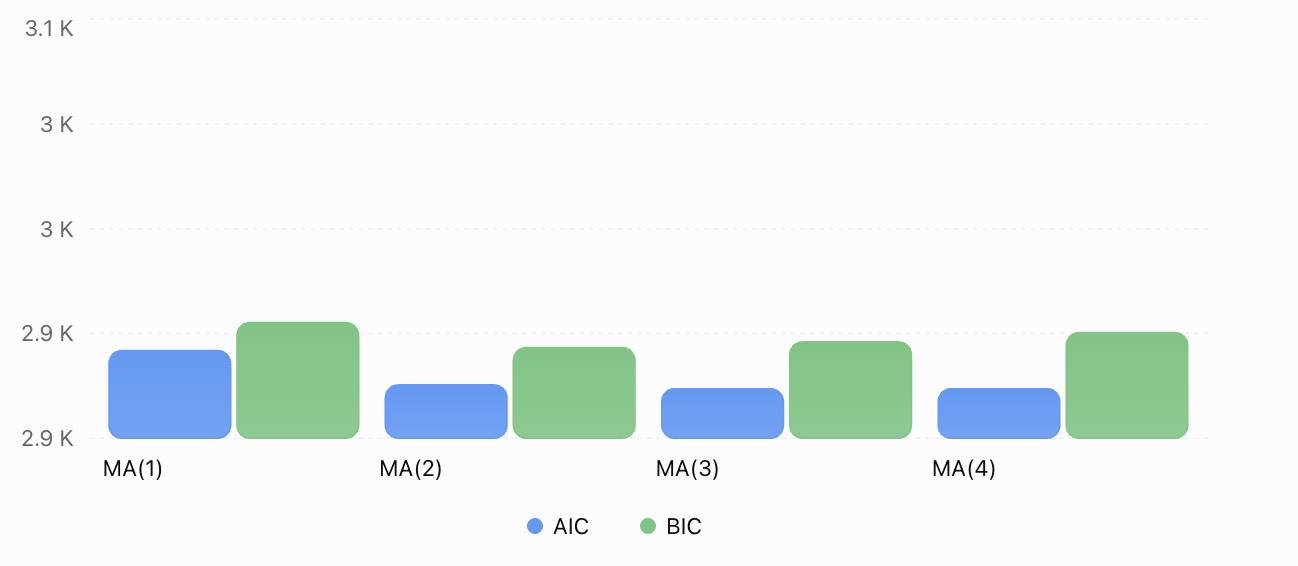

### Interpretación de los resultados

El criterio AIC presenta un empate entre MA(3) y MA(4):

$$AIC_{MA(3)}=AIC_{MA(4)}=2886$$

En cambio, BIC selecciona MA(2):

$$\boxed{BIC_{MA(2)}=2907.63}$$

¿Por qué ocurre esto?

Porque MA(3) y MA(4) ofrecen pequeñas mejoras en la verosimilitud, pero requieren parámetros adicionales.

BIC considera que dichas mejoras no justifican el incremento de complejidad.

Por tanto, AIC y BIC pueden seleccionar modelos diferentes sin que ninguno de los dos criterios esté calculado incorrectamente.

## 7. Diferencias de AIC y BIC entre modelos

En lugar de analizar únicamente los valores absolutos, es conveniente calcular las diferencias respecto al mejor modelo.

Para AIC:

$$\boxed{\Delta AIC_i=AIC_i-AIC_{\min}}$$

Para BIC:

$$\boxed{\Delta BIC_i=BIC_i-BIC_{\min}}$$

Estas diferencias permiten cuantificar el respaldo relativo que recibe cada modelo dentro del conjunto evaluado.

Para AIC se utilizan frecuentemente las siguientes orientaciones:

| $\Delta AIC$ | Interpretación orientativa |
| :---: | :--- |
| 0–2 | Respaldo sustancial o similar |
| 4–7 | Menor respaldo |
| Mayor que 10 | Respaldo muy reducido |

No son umbrales de significancia estadística ni reglas universales.

En nuestro ejemplo:

| Modelo | $\Delta AIC$ | $\Delta BIC$ |
| :--- | :---: | :---: |
| MA(1) | 20 | 13.09 |
| MA(2) | 2 | 0 |
| MA(3) | 0 | 2.91 |
| MA(4) | 0 | 7.82 |

Desde la perspectiva de AIC, MA(3) y MA(4) ofrecen el mejor valor.

Sin embargo, MA(2) se encuentra solamente dos unidades por encima del mínimo de AIC y utiliza menos parámetros.

Desde la perspectiva de BIC, MA(2) es claramente el candidato preferido entre los cuatro modelos.

## 8. ¿Por qué AIC y BIC pueden seleccionar modelos diferentes?

La razón se encuentra en sus fundamentos estadísticos.

### AIC: aproximación predictiva

AIC se fundamenta en la teoría de la información y en la aproximación de la divergencia de Kullback-Leibler.

Su objetivo es seleccionar un modelo que minimice, aproximadamente, la pérdida de información al representar el proceso generador de los datos.

Por ello, AIC está estrechamente relacionado con la calidad del ajuste probabilístico esperado sobre nuevos datos.

### BIC: selección de estructura

BIC surge de una aproximación asintótica de la evidencia bayesiana de los modelos, bajo determinadas condiciones de regularidad y supuestos sobre las probabilidades previas.

Cuando el modelo verdadero pertenece al conjunto de candidatos y se satisfacen los supuestos correspondientes, BIC posee una propiedad denominada consistencia en la selección de modelos.

Esto significa que, conforme aumenta el tamaño de la muestra, la probabilidad de seleccionar el modelo verdadero tiende a uno.

AIC no posee esa propiedad general: puede seguir seleccionando modelos con parámetros adicionales aun cuando la muestra crezca.

La comparación puede resumirse así:

| Característica | AIC | BIC |
| :--- | :--- | :--- |
| **Fundamento** | Teoría de la información | Aproximación bayesiana |
| **Penalización** | $2k$ | $k\ln(n)$ |
| **Depende de $n$ en la penalización** | No directamente | Sí |
| **Tendencia habitual** | Modelos más flexibles | Modelos más parsimoniosos |
| **Orientación principal** | Aproximación predictiva | Identificación de estructura |
| **Regla de selección** | Menor AIC | Menor BIC |

## 9. Aplicación de AIC y BIC en modelos AR y MA

Consideremos una familia de modelos ARMA(p,q):

$$X_t=c+\sum_{i=1}^{p}\phi_iX_{t-i} +\varepsilon_t+ \sum_{j=1}^{q}\theta_j\varepsilon_{t-j}$$

El modelo contiene:
- $p$ parámetros autorregresivos.
- $q$ parámetros de medias móviles.
- Un parámetro de nivel o intercepto, según la parametrización.
- Un parámetro de varianza de las innovaciones.

Para un modelo ARMA estacionario con media estimada y varianza desconocida, normalmente:

$$\boxed{k=p+q+2}$$

Así, los criterios pueden expresarse como:

$$AIC=-2\ln(\hat L)+2(p+q+2)$$

$$BIC=-2\ln(\hat L)+(p+q+2)\ln(n)$$

Esto permite comparar modelos de diferentes órdenes.

Por ejemplo:

$$AR(1), \quad AR(2), \quad MA(1), \quad MA(2), \quad ARMA(1,1)$$

La comparación es válida siempre que se utilice una base de observaciones equivalente y un procedimiento de cálculo de la verosimilitud compatible.

## 10. Relación entre AIC, BIC y RMSE

Es importante distinguir los criterios de información de las métricas de predicción.

El error cuadrático medio se define como:

$$MSE=\frac{1}{n}\sum_{t=1}^{n}(X_t-\hat X_t)^2$$

Y su raíz:

$$\boxed{RMSE=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(X_t-\hat X_t)^2}}$$

Mientras AIC y BIC evalúan el equilibrio entre ajuste probabilístico y complejidad, RMSE cuantifica directamente el error de las predicciones.

Un modelo con menor AIC no necesariamente tendrá menor RMSE en el conjunto de prueba.

Por ejemplo, consideremos estos valores hipotéticos para ilustrar la diferencia entre selección estadística y precisión predictiva:

| Modelo | AIC | BIC | RMSE de prueba |
| :--- | :---: | :---: | :---: |
| AR(1) | 2850 | 2865 | 0.42 °C |
| AR(2) | 2835 | 2855 | 0.36 °C |
| MA(2) | 2840 | 2860 | 0.48 °C |
| ARMA(1,1) | 2830 | 2850 | 0.39 °C |

En este ejemplo:
- **AIC** selecciona $ARMA(1,1)$.
- **BIC** también selecciona $ARMA(1,1)$.
- **RMSE** selecciona $AR(2)$.

Si nuestro objetivo principal es pronosticar temperatura, el desempeño fuera de muestra constituye una evidencia fundamental.

## 11. Limitaciones de AIC y BIC

Aunque son herramientas estadísticas ampliamente utilizadas, presentan limitaciones que deben considerarse:

* **Dependencia del conjunto de modelos candidatos:** AIC y BIC identifican el mejor modelo dentro de los evaluados, no necesariamente el mejor modelo posible.
* **Sensibilidad a la especificación probabilística:** Si la distribución asumida para las innovaciones es inadecuada, los valores de verosimilitud pueden conducir a comparaciones poco representativas.
* **No sustituyen el análisis de residuales:** Un modelo puede tener un AIC reducido y aun así presentar autocorrelación significativa en sus residuales.
* **No garantizan precisión predictiva:** El modelo seleccionado puede comportarse deficientemente frente a cambios de régimen, tendencias o variaciones estacionales.
* **Diferencias en el cálculo de la verosimilitud:** No deben compararse indiscriminadamente valores de AIC/BIC obtenidos con distintas muestras, transformaciones de la variable o definiciones de verosimilitud.

Además, para muestras pequeñas puede ser conveniente utilizar el **AIC corregido (AICc)**, cuya forma habitual es:

$$\boxed{AICc=AIC+\frac{2k(k+1)}{n-k-1}}$$

Esta expresión requiere $n > k+1$ y resulta especialmente útil cuando el tamaño de la muestra es reducido respecto al número de parámetros.

## 12. Fundamento matemático para la automatización

Para el modelo autorregresivo $AR(p)$:

$$T_t=c+\sum_{i=1}^{p}\phi_iT_{t-i}+\varepsilon_t$$

Para el modelo de medias móviles $MA(q)$:

$$T_t=\mu+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j}$$

Los criterios se calcularán mediante:

$$\boxed{AIC=-2\ln(\hat L)+2k}$$

$$\boxed{BIC=-2\ln(\hat L)+k\ln(n)}$$

Donde $k$ representa el número de parámetros estimados, $n$ el número de observaciones utilizadas y $\hat L$ la máxima verosimilitud del modelo.

El script permitirá identificar qué orden de $AR$ y $MA$ ofrece el menor AIC y BIC, y posteriormente comparar ambas familias de modelos.

Seleccione el archivo datos_clima(2).csv


Saving datos_clima.csv to datos_clima.csv

Dimensiones: (7128, 4)

Columnas: ['Fecha', 'Hora', 'T', 'HR']

Primeros registros:
      Fecha      Hora      T     HR
0  07/10/26  16:24:00  22.55  66.45
1  07/10/26  16:25:00  22.62  66.39
2  07/10/26  16:26:00  22.69  66.22
3  07/10/26  16:27:00  22.79  66.66
4  07/10/26  16:28:00  22.88  65.95

Distribución de intervalos:
FechaHora
0 days 00:01:00    7126
0 days 01:32:00       1
Name: count, dtype: int64

Segmentos continuos:
segmento
1    4477
2    2651
dtype: int64

Registros del segmento seleccionado: 4477

Entrenamiento: 3581
Prueba: 896


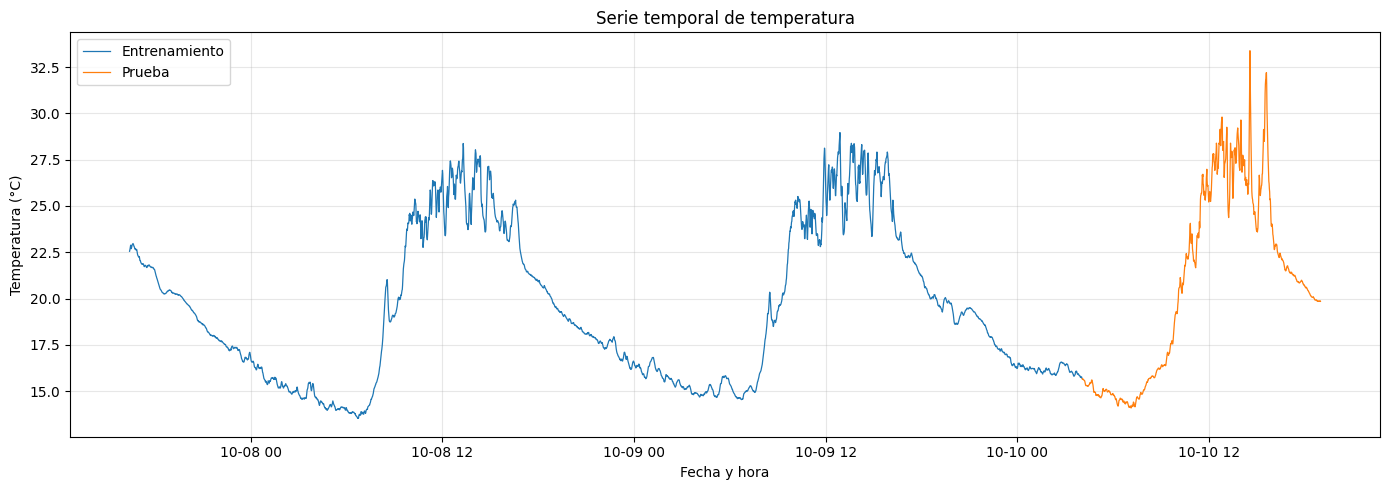


PRUEBA AUGMENTED DICKEY-FULLER
Estadístico ADF: -1.363826
p-valor: 0.599490
No se rechaza la hipótesis de raíz unitaria.
Interpretar con cautela los modelos AR/MA puros.
Estimando AR(1)...
Estimando AR(2)...
Estimando AR(3)...
Estimando AR(4)...
Estimando AR(5)...
Estimando AR(6)...
Estimando AR(7)...
Estimando AR(8)...
Estimando AR(9)...
Estimando AR(10)...
Estimando MA(1)...
Estimando MA(2)...
Estimando MA(3)...
Estimando MA(4)...
Estimando MA(5)...
Estimando MA(6)...
Estimando MA(7)...
Estimando MA(8)...
Estimando MA(9)...
Estimando MA(10)...

COMPARACIÓN DE MODELOS AR Y MA
Modelo Familia  Orden        AIC        BIC     LogLik  Parametros  Delta_AIC  Delta_BIC
 AR(9)      AR      9 -5212.1565 -5144.1391  2617.0782          11     0.0000    23.2418
AR(10)      AR     10 -5211.5020 -5137.3012  2617.7510          12     0.6545    30.0797
 AR(8)      AR      8 -5210.7825 -5148.9485  2615.3913          10     1.3740    18.4324
 AR(5)      AR      5 -5210.6647 -5167.3809  2612.3323     

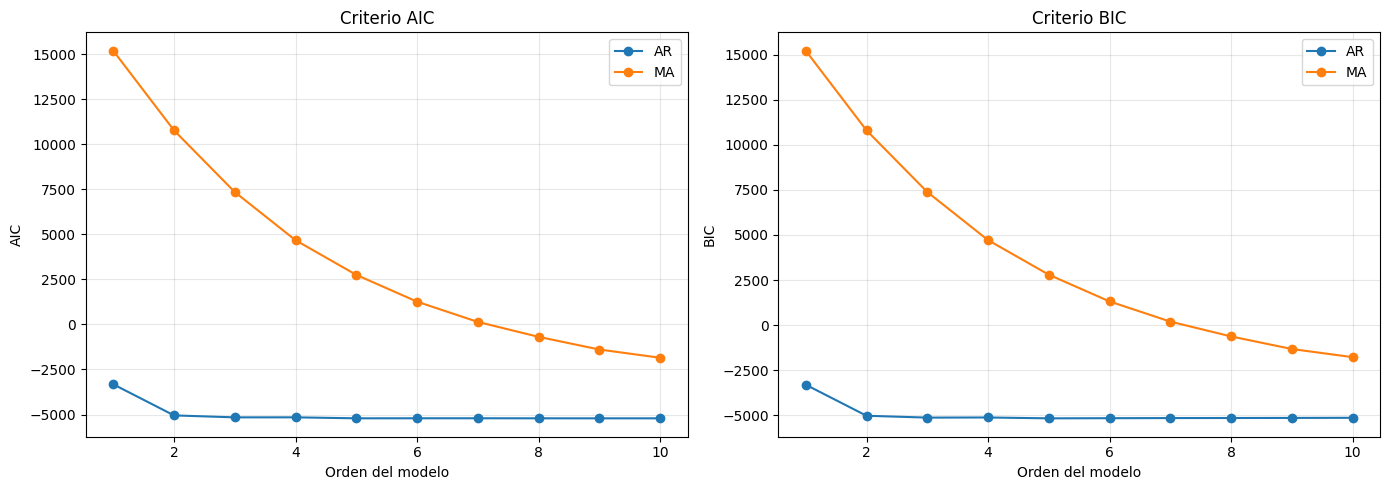

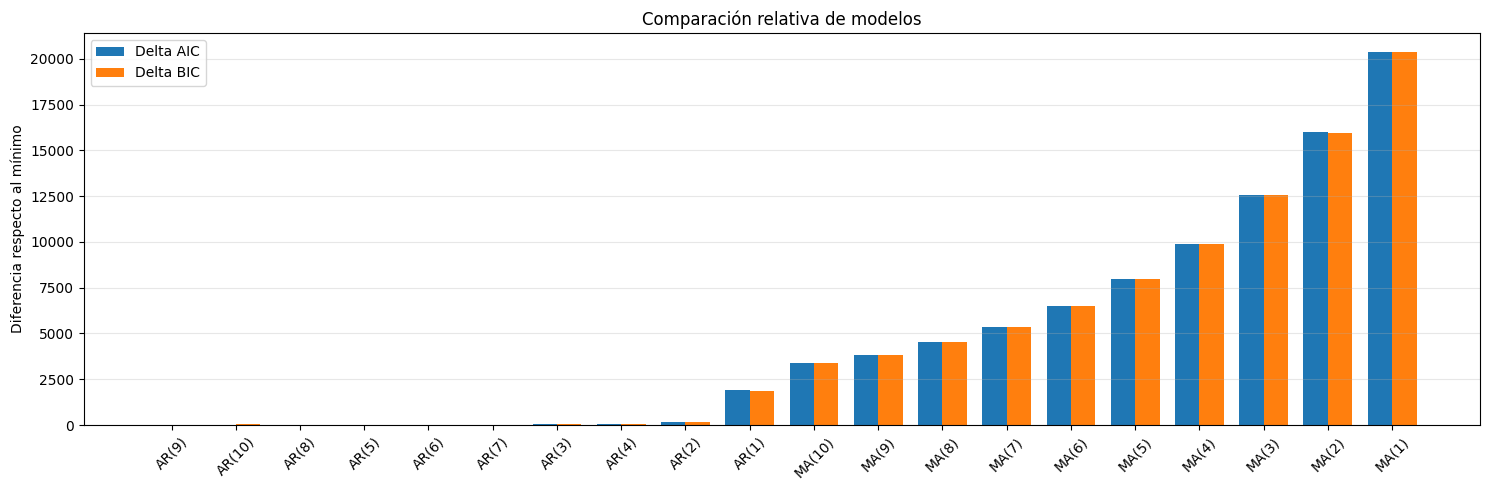


EVALUACIÓN EN CONJUNTO DE PRUEBA
Modelo     RMSE      MAE
 AR(5) 5.535368 4.274115
 AR(9) 5.429941 4.200930


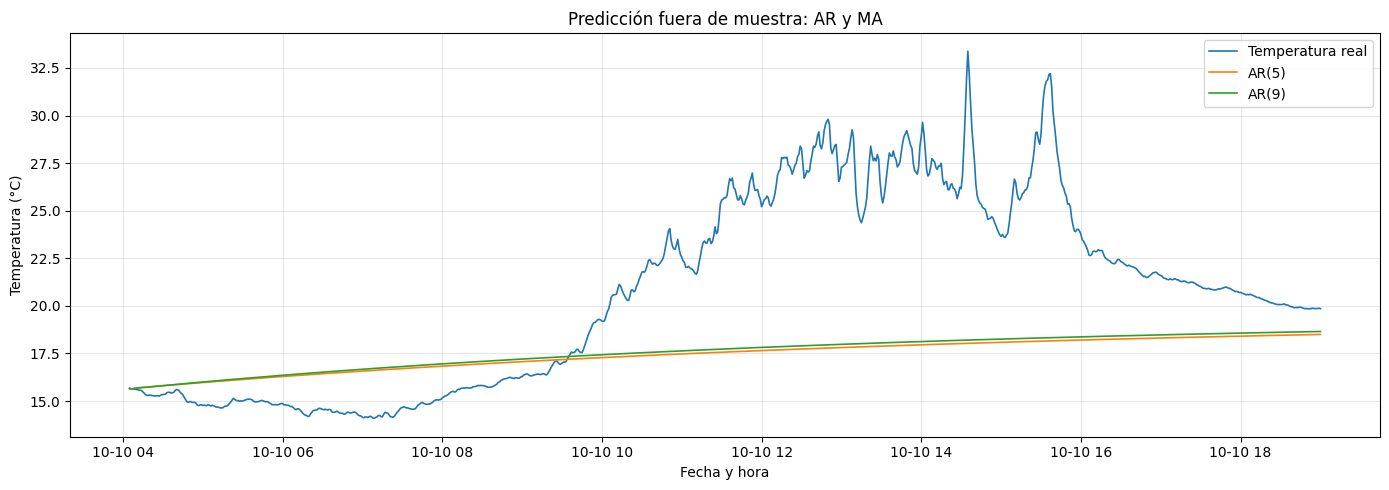


RESUMEN DEL MODELO SELECCIONADO POR AIC
                               SARIMAX Results                                
Dep. Variable:                      T   No. Observations:                 3581
Model:                 ARIMA(9, 0, 0)   Log Likelihood                2617.078
Date:                Tue, 03 Nov 2026   AIC                          -5212.156
Time:                        00:22:18   BIC                          -5144.139
Sample:                    10-07-2026   HQIC                         -5187.910
                         - 10-10-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.3664      3.344      5.792      0.000      12.813      25.920
ar.L1          1.7226      0.007    242.732      0.000       1.709       1.737
ar.L2      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# COMPARACIÓN DE MODELOS AR(p) Y MA(q)
# CRITERIOS AIC Y BIC
# Dataset: datos_clima(2).csv
# Variable: Temperatura (T)
# Entorno: Google Colab
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from google.colab import files
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

VARIABLE = "T"
ORDEN_MAX = 10
PORCENTAJE_TRAIN = 0.80

# ============================================================
# 2. CARGA DE DATOS
# ============================================================

print("Seleccione el archivo datos_clima(2).csv")
uploaded = files.upload()

nombre = next(iter(uploaded))

df = pd.read_csv(nombre, encoding="utf-8-sig")

print("\nDimensiones:", df.shape)
print("\nColumnas:", df.columns.tolist())
print("\nPrimeros registros:")
print(df.head())

# ============================================================
# 3. PREPARACIÓN DE LA SERIE TEMPORAL
# ============================================================

df["FechaHora"] = pd.to_datetime(
    df["Fecha"].astype(str) + " " + df["Hora"].astype(str),
    format="%d/%m/%y %H:%M:%S",
    errors="coerce"
)

df[VARIABLE] = pd.to_numeric(
    df[VARIABLE],
    errors="coerce"
)

df = (
    df.dropna(subset=["FechaHora", VARIABLE])
      .sort_values("FechaHora")
      .drop_duplicates("FechaHora")
      .reset_index(drop=True)
)

# Identificar intervalos de muestreo
intervalos = df["FechaHora"].diff()

print("\nDistribución de intervalos:")
print(intervalos.value_counts().head(10))

# Seleccionar el segmento continuo más largo
nuevo_segmento = intervalos.ne(
    pd.Timedelta(minutes=1)
)

df["segmento"] = nuevo_segmento.cumsum()

conteo = df.groupby("segmento").size()

print("\nSegmentos continuos:")
print(conteo)

segmento_principal = conteo.idxmax()

serie = (
    df.loc[
        df["segmento"] == segmento_principal,
        ["FechaHora", VARIABLE]
    ]
    .set_index("FechaHora")[VARIABLE]
    .asfreq("min")
)

print("\nRegistros del segmento seleccionado:", len(serie))

# ============================================================
# 4. PARTICIÓN CRONOLÓGICA
# ============================================================

n_train = int(len(serie) * PORCENTAJE_TRAIN)

train = serie.iloc[:n_train]
test = serie.iloc[n_train:]

print("\nEntrenamiento:", len(train))
print("Prueba:", len(test))

# ============================================================
# 5. VISUALIZACIÓN
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train.values,
    label="Entrenamiento",
    linewidth=0.9
)

plt.plot(
    test.index,
    test.values,
    label="Prueba",
    linewidth=0.9
)

plt.title("Serie temporal de temperatura")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 6. PRUEBA DE ESTACIONARIEDAD ADF
# ============================================================

adf = adfuller(train, autolag="AIC")

print("\nPRUEBA AUGMENTED DICKEY-FULLER")
print(f"Estadístico ADF: {adf[0]:.6f}")
print(f"p-valor: {adf[1]:.6f}")

if adf[1] < 0.05:
    print("Se rechaza la hipótesis de raíz unitaria.")
else:
    print("No se rechaza la hipótesis de raíz unitaria.")
    print("Interpretar con cautela los modelos AR/MA puros.")

# ============================================================
# 7. ESTIMACIÓN DE MODELOS AR(p)
# ============================================================

resultados = []
modelos = {}

for p in range(1, ORDEN_MAX + 1):

    print(f"Estimando AR({p})...")

    try:
        modelo = ARIMA(
            train,
            order=(p, 0, 0),
            trend="c",
            enforce_stationarity=True,
            enforce_invertibility=True
        )

        ajuste = modelo.fit()

        modelos[("AR", p)] = ajuste

        resultados.append({
            "Modelo": f"AR({p})",
            "Familia": "AR",
            "Orden": p,
            "AIC": ajuste.aic,
            "BIC": ajuste.bic,
            "LogLik": ajuste.llf,
            "Parametros": len(ajuste.params)
        })

    except Exception as e:
        print(f"Error AR({p}): {e}")

# ============================================================
# 8. ESTIMACIÓN DE MODELOS MA(q)
# ============================================================

for q in range(1, ORDEN_MAX + 1):

    print(f"Estimando MA({q})...")

    try:
        modelo = ARIMA(
            train,
            order=(0, 0, q),
            trend="c",
            enforce_stationarity=True,
            enforce_invertibility=True
        )

        ajuste = modelo.fit()

        modelos[("MA", q)] = ajuste

        resultados.append({
            "Modelo": f"MA({q})",
            "Familia": "MA",
            "Orden": q,
            "AIC": ajuste.aic,
            "BIC": ajuste.bic,
            "LogLik": ajuste.llf,
            "Parametros": len(ajuste.params)
        })

    except Exception as e:
        print(f"Error MA({q}): {e}")

# ============================================================
# 9. TABLA COMPARATIVA
# ============================================================

tabla = pd.DataFrame(resultados)

if tabla.empty:
    raise RuntimeError("No fue posible estimar ningún modelo.")

tabla = tabla.sort_values("AIC").reset_index(drop=True)

tabla["Delta_AIC"] = tabla["AIC"] - tabla["AIC"].min()
tabla["Delta_BIC"] = tabla["BIC"] - tabla["BIC"].min()

print("\n======================================")
print("COMPARACIÓN DE MODELOS AR Y MA")
print("======================================")

print(tabla.round(4).to_string(index=False))

# ============================================================
# 10. MEJORES MODELOS SEGÚN AIC Y BIC
# ============================================================

mejor_aic = tabla.loc[tabla["AIC"].idxmin()]
mejor_bic = tabla.loc[tabla["BIC"].idxmin()]

print("\nMEJOR MODELO SEGÚN AIC")
print(mejor_aic[["Modelo", "AIC", "BIC"]])

print("\nMEJOR MODELO SEGÚN BIC")
print(mejor_bic[["Modelo", "AIC", "BIC"]])

# ============================================================
# 11. GRÁFICAS AIC Y BIC CONTRA EL ORDEN
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for familia in ["AR", "MA"]:

    datos = tabla[tabla["Familia"] == familia]
    datos = datos.sort_values("Orden")

    axes[0].plot(
        datos["Orden"],
        datos["AIC"],
        marker="o",
        label=familia
    )

    axes[1].plot(
        datos["Orden"],
        datos["BIC"],
        marker="o",
        label=familia
    )

axes[0].set_title("Criterio AIC")
axes[0].set_xlabel("Orden del modelo")
axes[0].set_ylabel("AIC")

axes[1].set_title("Criterio BIC")
axes[1].set_xlabel("Orden del modelo")
axes[1].set_ylabel("BIC")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 12. GRÁFICA DE DIFERENCIAS DE AIC Y BIC
# ============================================================

tabla_ordenada = tabla.sort_values("AIC")

x = np.arange(len(tabla_ordenada))
ancho = 0.38

plt.figure(figsize=(15, 5))

plt.bar(
    x - ancho / 2,
    tabla_ordenada["Delta_AIC"],
    width=ancho,
    label="Delta AIC"
)

plt.bar(
    x + ancho / 2,
    tabla_ordenada["Delta_BIC"],
    width=ancho,
    label="Delta BIC"
)

plt.xticks(
    x,
    tabla_ordenada["Modelo"],
    rotation=45
)

plt.ylabel("Diferencia respecto al mínimo")
plt.title("Comparación relativa de modelos")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 13. EVALUACIÓN PREDICTIVA
# ============================================================

# Evaluamos los modelos elegidos por AIC y BIC.
# El pronóstico se realiza desde el final del entrenamiento.
# Las observaciones de prueba no intervienen en el ajuste.

seleccionados = {
    (
        mejor_aic["Familia"],
        int(mejor_aic["Orden"])
    ),
    (
        mejor_bic["Familia"],
        int(mejor_bic["Orden"])
    )
}

metricas = []
predicciones = pd.DataFrame(index=test.index)
predicciones["Real"] = test.values

for familia, orden in sorted(seleccionados):

    ajuste = modelos[(familia, orden)]
    nombre_modelo = f"{familia}({orden})"

    pronostico = ajuste.forecast(steps=len(test))
    y_pred = np.asarray(pronostico)

    rmse = np.sqrt(
        mean_squared_error(test.values, y_pred)
    )

    mae = mean_absolute_error(test.values, y_pred)

    metricas.append({
        "Modelo": nombre_modelo,
        "RMSE": rmse,
        "MAE": mae
    })

    predicciones[nombre_modelo] = y_pred

tabla_metricas = pd.DataFrame(metricas)

print("\nEVALUACIÓN EN CONJUNTO DE PRUEBA")
print(tabla_metricas.round(6).to_string(index=False))

# ============================================================
# 14. GRÁFICA DE PREDICCIONES
# ============================================================

plt.figure(figsize=(14, 5))

plt.plot(
    predicciones.index,
    predicciones["Real"],
    label="Temperatura real",
    linewidth=1.2
)

for familia, orden in sorted(seleccionados):

    nombre_modelo = f"{familia}({orden})"

    plt.plot(
        predicciones.index,
        predicciones[nombre_modelo],
        label=nombre_modelo,
        linewidth=1.2
    )

plt.title("Predicción fuera de muestra: AR y MA")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 15. PARÁMETROS DEL MODELO SELECCIONADO POR AIC
# ============================================================

clave = (
    mejor_aic["Familia"],
    int(mejor_aic["Orden"])
)

modelo_final = modelos[clave]

print("\nRESUMEN DEL MODELO SELECCIONADO POR AIC")
print(modelo_final.summary())

# ============================================================
# 16. EXPORTAR RESULTADOS
# ============================================================

tabla.to_csv(
    "comparacion_AIC_BIC_AR_MA.csv",
    index=False
)

tabla_metricas.to_csv(
    "metricas_AR_MA.csv",
    index=False
)

predicciones.to_csv(
    "predicciones_AR_MA.csv",
    index_label="FechaHora"
)

print("\nArchivos generados correctamente.")

files.download("comparacion_AIC_BIC_AR_MA.csv")
files.download("metricas_AR_MA.csv")
files.download("predicciones_AR_MA.csv")


Seleccione el archivo CSV


Saving comparacion_AIC_BIC_AR_MA.csv to comparacion_AIC_BIC_AR_MA (1).csv

Dimensiones del dataset:
(20, 9)

Columnas disponibles:
['Modelo', 'Familia', 'Orden', 'AIC', 'BIC', 'LogLik', 'Parametros', 'Delta_AIC', 'Delta_BIC']

Primeros registros:


,Modelo,Familia,Orden,AIC,BIC,LogLik,Parametros,Delta_AIC,Delta_BIC
0,AR(9),AR,9,-5212.156468,-5144.139097,2617.078234,11,0.000000,23.241810
1,AR(10),AR,10,-5211.501981,-5137.301213,2617.750991,12,0.654487,30.079695
2,AR(8),AR,8,-5210.782512,-5148.948539,2615.391256,10,1.373956,18.432369
3,AR(5),AR,5,-5210.664689,-5167.380908,2612.332345,7,1.491779,0.000000
4,AR(6),AR,6,-5209.206261,-5159.739082,2612.603130,8,2.950208,7.641826



Variables numéricas:
['Orden', 'AIC', 'BIC', 'LogLik', 'Parametros', 'Delta_AIC', 'Delta_BIC']


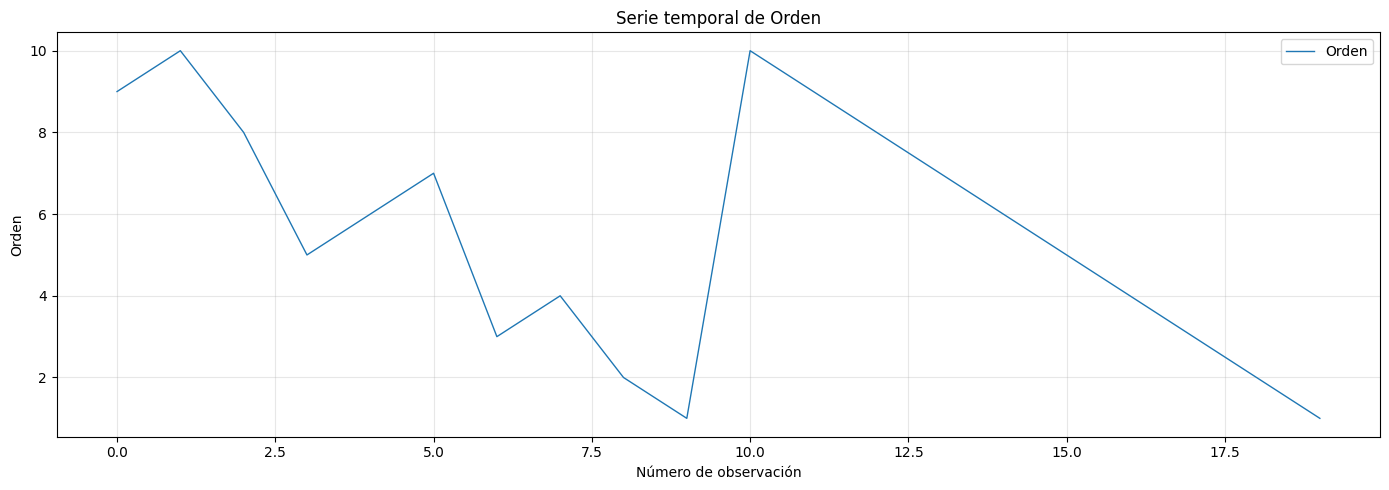

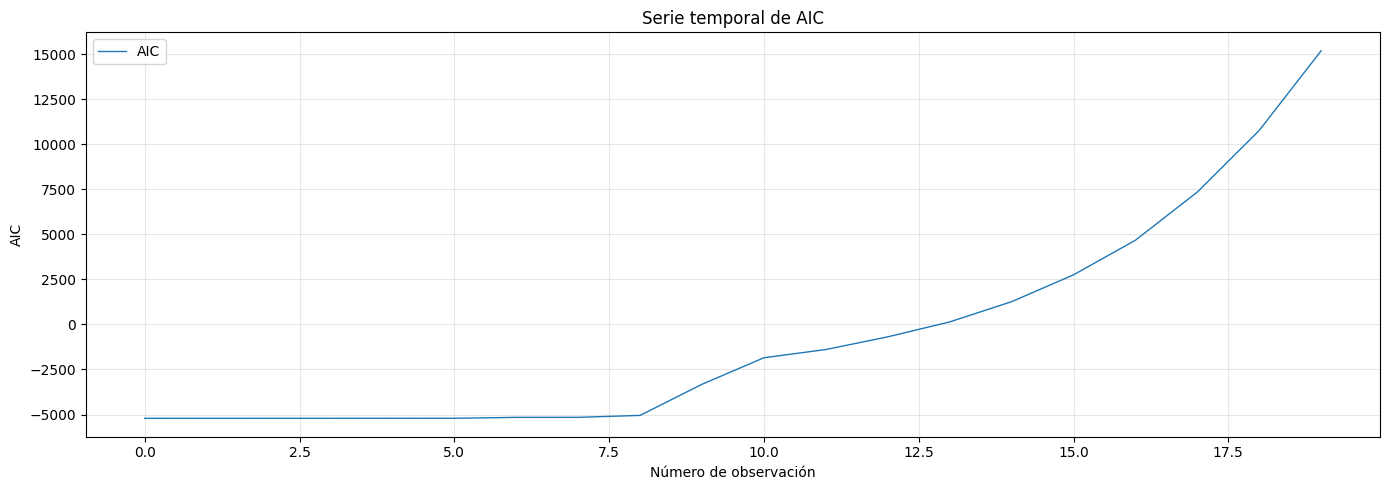

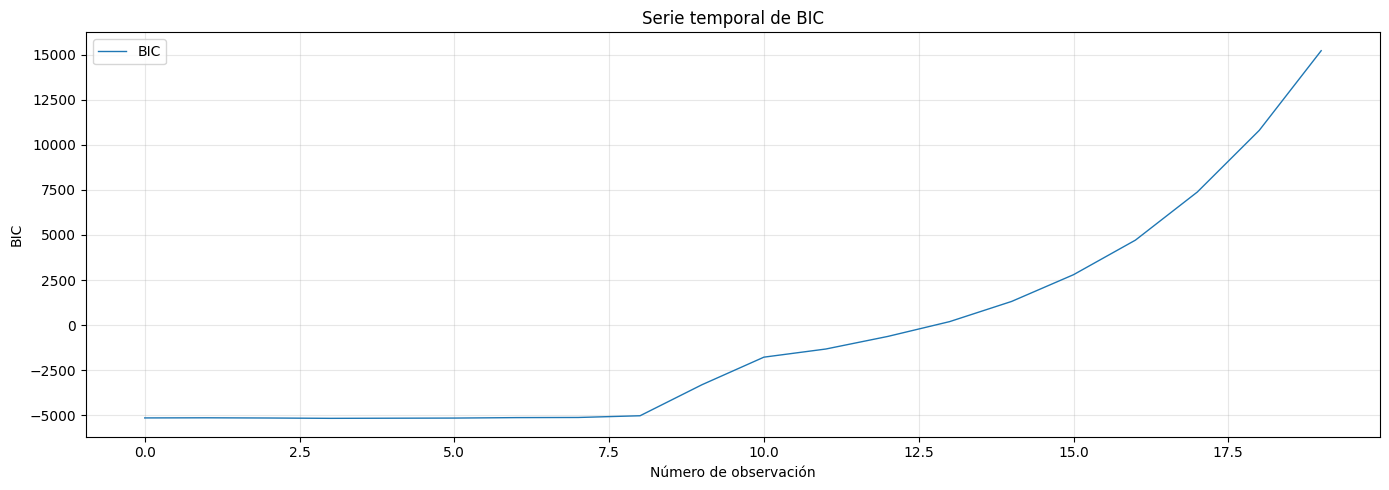

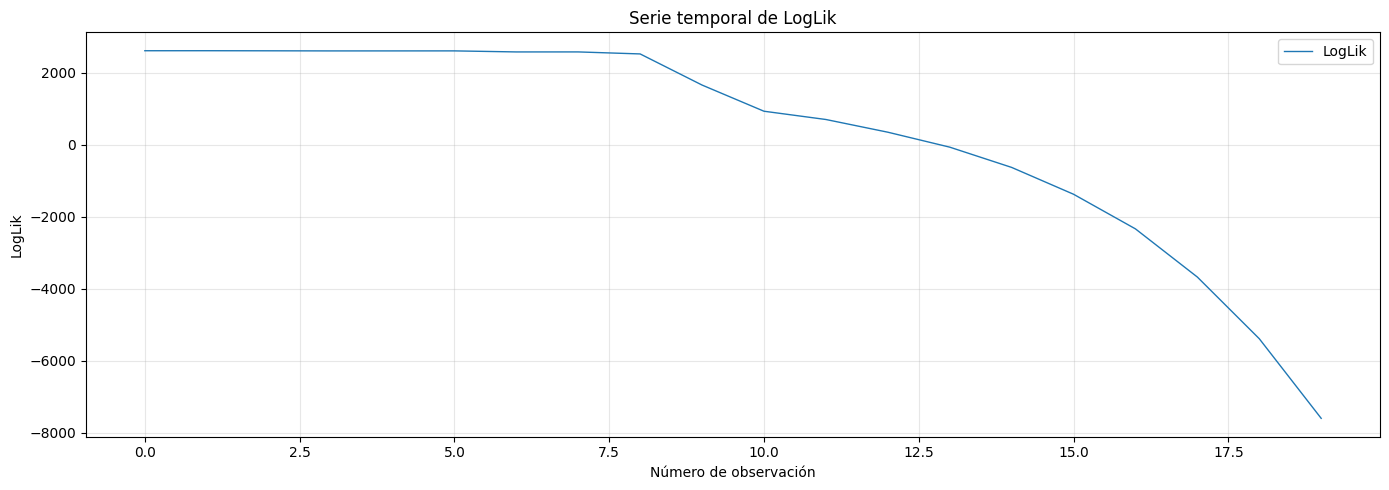

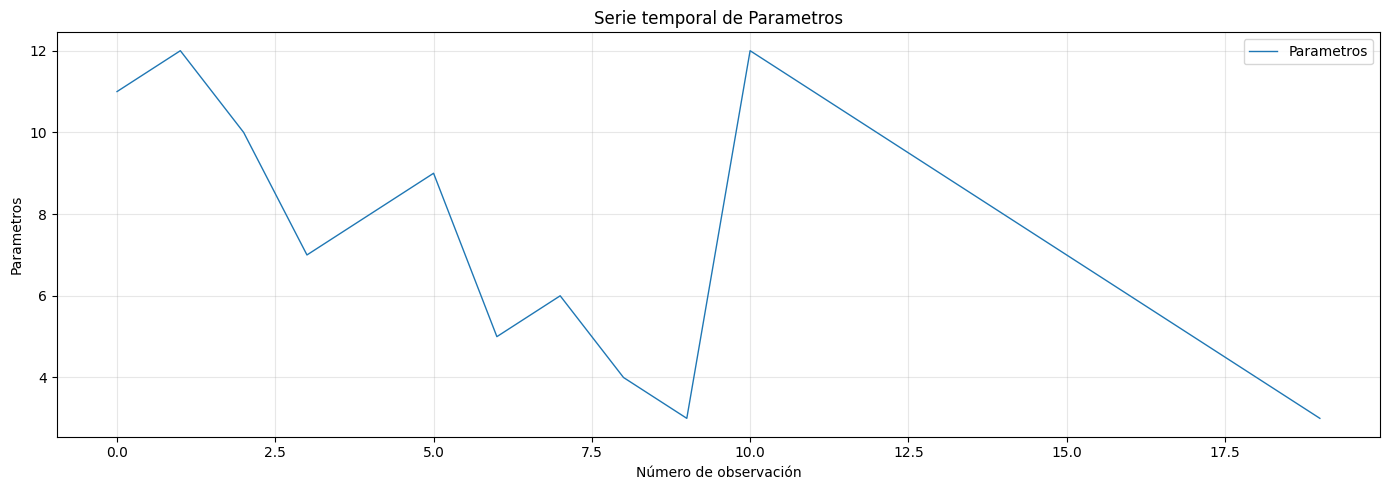

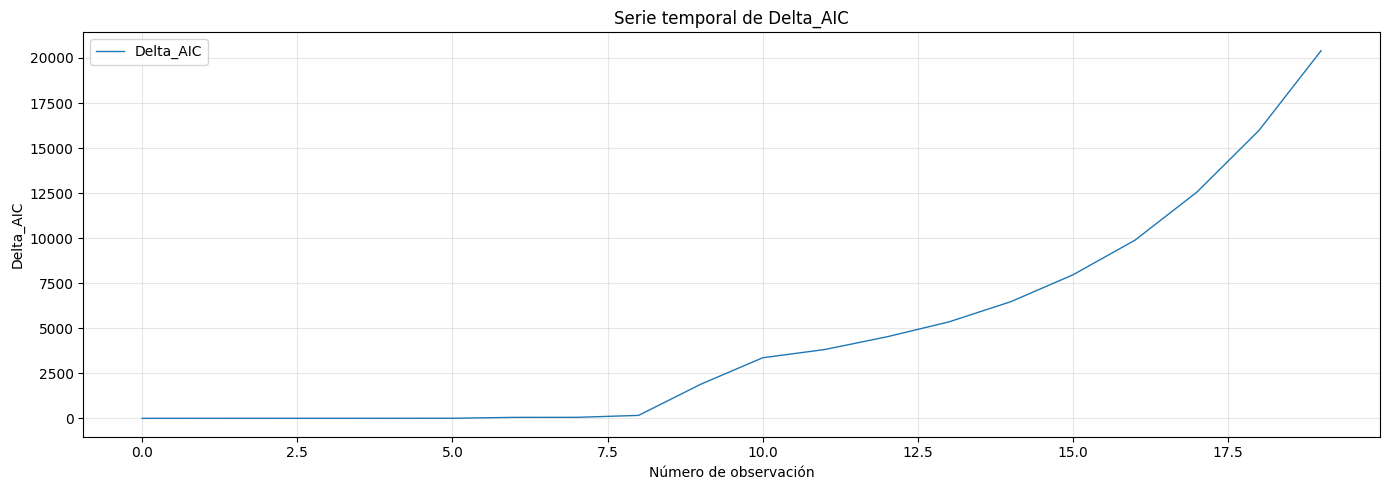

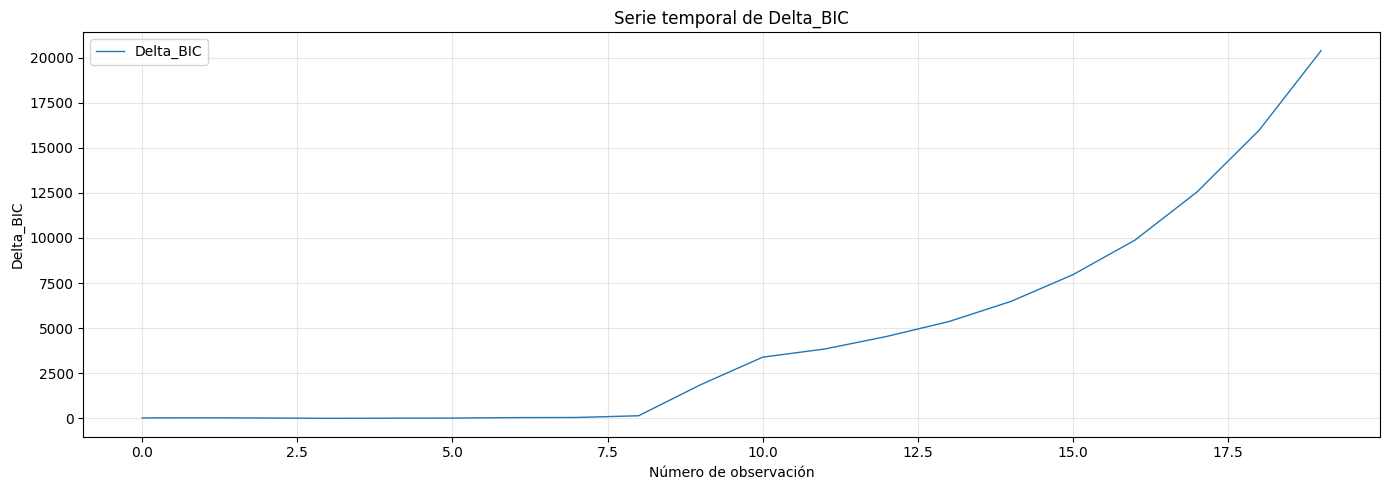

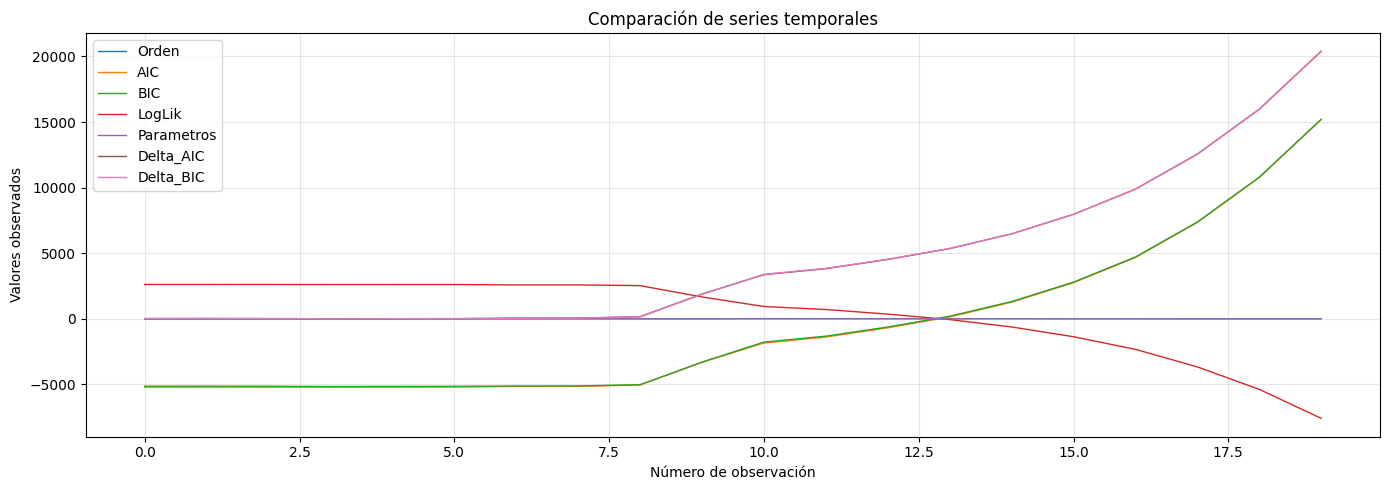


Visualización finalizada.


In [2]:

# =====================================================
# VISUALIZACIÓN DE SERIES DE TIEMPO DESDE UN ARCHIVO CSV
# Entorno: Google Colab
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# 1. Cargar archivo CSV
print("Seleccione el archivo CSV")
uploaded = files.upload()

nombre_archivo = next(iter(uploaded))

df = pd.read_csv(nombre_archivo, encoding="utf-8-sig")

# 2. Información general
print("\nDimensiones del dataset:")
print(df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeros registros:")
display(df.head())

# 3. Construir columna temporal, si existe
if {"Fecha", "Hora"}.issubset(df.columns):

    df["FechaHora"] = pd.to_datetime(
        df["Fecha"].astype(str) + " " +
        df["Hora"].astype(str),
        dayfirst=True,
        errors="coerce"
    )

elif "FechaHora" in df.columns:

    df["FechaHora"] = pd.to_datetime(
        df["FechaHora"],
        dayfirst=True,
        errors="coerce"
    )

# 4. Seleccionar eje horizontal
if "FechaHora" in df.columns:

    df = df.dropna(subset=["FechaHora"])
    df = df.sort_values("FechaHora")
    eje_x = df["FechaHora"]
    etiqueta_x = "Fecha y hora"

else:
    eje_x = df.index
    etiqueta_x = "Número de observación"

# 5. Identificar variables numéricas
excluir = ["FechaHora"]

for columna in df.columns:

    if columna not in excluir:
        convertido = pd.to_numeric(
            df[columna],
            errors="coerce"
        )

        if convertido.notna().sum() > 0:
            df[columna] = convertido

variables = df.select_dtypes(
    include="number"
).columns.tolist()

print("\nVariables numéricas:")
print(variables)

# 6. Graficar cada variable
for variable in variables:

    plt.figure(figsize=(14, 5))

    plt.plot(
        eje_x,
        df[variable],
        linewidth=1,
        label=variable
    )

    plt.title(f"Serie temporal de {variable}")
    plt.xlabel(etiqueta_x)
    plt.ylabel(variable)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# 7. Gráfica conjunta de variables
plt.figure(figsize=(14, 5))

for variable in variables:

    plt.plot(
        eje_x,
        df[variable],
        linewidth=1,
        label=variable
    )

plt.title("Comparación de series temporales")
plt.xlabel(etiqueta_x)
plt.ylabel("Valores observados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nVisualización finalizada.")
